<a href="https://colab.research.google.com/github/gopalwagh/Statistics-For-Machine-Learning-Practical/blob/main/practical9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EXPERIMENT 9: Implementation of k-Nearest Neighbour Estimate

In [1]:
import numpy as np
from collections import Counter


In [2]:

# Training Data
X_train = np.array([
    [1, 1],
    [2, 2],
    [2, 1],
    [3, 2],
    [6, 6],
    [7, 7],
    [7, 6],
    [8, 7]
])

# Class Labels
y_train = np.array([
    "Class A",
    "Class A",
    "Class A",
    "Class A",
    "Class B",
    "Class B",
    "Class B",
    "Class B"
])

# Test Sample

X_test = np.array([4, 4])

# Number of Nearest Neighbors

k = 3

distance_list = []

for i in range(len(X_train)):
    distance = np.sqrt(
        np.sum((X_train[i] - X_test) ** 2)
    )
    distance_list.append((distance, y_train[i]))

distance_list.sort(key=lambda x: x[0])
print("Sorted Distances:")

for item in distance_list:
    print(item)

nearest = distance_list[:k]
labels = [item[1] for item in nearest]
prediction = Counter(labels).most_common(1)[0][0]

print("\nNearest Neighbours:")
print(nearest)

print("\nPredicted Class:", prediction)

Sorted Distances:
(np.float64(2.23606797749979), np.str_('Class A'))
(np.float64(2.8284271247461903), np.str_('Class A'))
(np.float64(2.8284271247461903), np.str_('Class B'))
(np.float64(3.605551275463989), np.str_('Class A'))
(np.float64(3.605551275463989), np.str_('Class B'))
(np.float64(4.242640687119285), np.str_('Class A'))
(np.float64(4.242640687119285), np.str_('Class B'))
(np.float64(5.0), np.str_('Class B'))

Nearest Neighbours:
[(np.float64(2.23606797749979), np.str_('Class A')), (np.float64(2.8284271247461903), np.str_('Class A')), (np.float64(2.8284271247461903), np.str_('Class B'))]

Predicted Class: Class A


# EXPERIMENT 9: Implementation of k-Nearest Neighbour Estimate

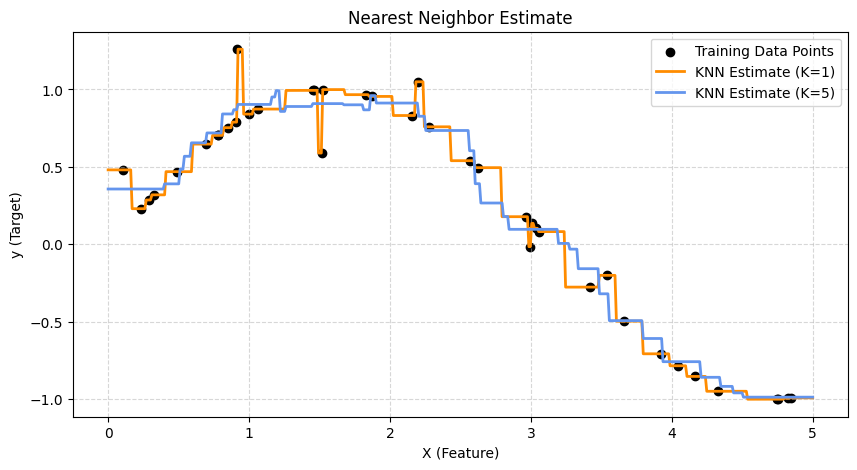

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor

np.random.seed(42)

X = np.sort(5 * np.random.rand(40, 1), axis=0)
y = np.sin(X).ravel()

y[::5] += 1 * (0.5 - np.random.rand(8))

T = np.linspace(0, 5, 500)[:, np.newaxis]

knn_1 = KNeighborsRegressor(n_neighbors=1)
knn_5 = KNeighborsRegressor(n_neighbors=5)

y_pred_1 = knn_1.fit(X, y).predict(T)
y_pred_5 = knn_5.fit(X, y).predict(T)

plt.figure(figsize=(10, 5))

plt.scatter(
    X,y, color='black',
    label='Training Data Points'
)

plt.plot(
    T,
    y_pred_1,
    color='darkorange',
    lw=2,
    label='KNN Estimate (K=1)'
)

plt.plot(
    T,y_pred_5,
    color='cornflowerblue',
    lw=2,
    label='KNN Estimate (K=5)'
)

plt.xlabel('X (Feature)')
plt.ylabel('y (Target)')
plt.title('Nearest Neighbor Estimate')
plt.legend(loc='upper right')

plt.grid(True, linestyle='--', alpha=0.5)

plt.show()